In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
data = pd.read_csv('/content/drive/MyDrive/OnlineRetail.csv' , encoding='latin1'
)

data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [8]:
data.info()
uk_data = data.copy()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


**Data Cleaning and Validation**

In [9]:
uk_data = uk_data[ uk_data['Country'] == 'United Kingdom']
uk_data = uk_data.dropna(subset=['CustomerID'])

print("Negative quantities:", (uk_data['Quantity'] < 0).sum())
print("Zero or negative prices:", (uk_data['UnitPrice'] <= 0).sum())

Negative quantities: 7533
Zero or negative prices: 24


We selected customers from the United Kingdom and removed rows with missing CustomerID values because we need to identify customers across different months.

We also checked for invalid transactions:
- **7,533** rows have negative quantities.
- **24** rows have zero or negative prices.

These transactions need to be handled before calculating the monthly retention rate.

In [11]:
uk_data['InvoiceDate'] = pd.to_datetime(uk_data['InvoiceDate'])

uk_data['InvoiceMonth'] = (
    uk_data['InvoiceDate'].dt.year * 100
    + uk_data['InvoiceDate'].dt.month
)
uk_data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,201012
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,201012
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,201012
...,...,...,...,...,...,...,...,...,...
541889,581585,22466,FAIRY TALE COTTAGE NIGHT LIGHT,12,2011-12-09 12:31:00,1.95,15804.0,United Kingdom,201112
541890,581586,22061,LARGE CAKE STAND HANGING STRAWBERY,8,2011-12-09 12:49:00,2.95,13113.0,United Kingdom,201112
541891,581586,23275,SET OF 3 HANGING OWLS OLLIE BEAK,24,2011-12-09 12:49:00,1.25,13113.0,United Kingdom,201112
541892,581586,21217,RED RETROSPOT ROUND CAKE TINS,24,2011-12-09 12:49:00,8.95,13113.0,United Kingdom,201112


We converted the InvoiceDate column to datetime and created a new column called InvoiceMonth.

We multiplied the year by 100 and added the month to create a six-digit number (YYYYMM). This helps us group customer purchases by month.

In [12]:
customer_activity = pd.crosstab(
    uk_data['CustomerID'],
    uk_data['InvoiceMonth']
)
customer_activity = (customer_activity > 0).astype(int)
customer_activity.head()

InvoiceMonth,201012,201101,201102,201103,201104,201105,201106,201107,201108,201109,201110,201111,201112
CustomerID,,,,,,,,,,,,,
12346.0,0,1,0,0,0,0,0,0,0,0,0,0,0
12747.0,1,1,0,1,0,1,1,0,1,0,1,1,1
12748.0,1,1,1,1,1,1,1,1,1,1,1,1,1
12749.0,0,0,0,0,0,1,0,0,1,0,0,1,1
12820.0,0,1,0,0,0,0,0,0,0,1,1,0,1


In [13]:
total_customers = customer_activity.sum(axis=0)

total_customers

,0
InvoiceMonth,
201012,871
201101,684
201102,714
201103,923
201104,817
201105,985
201106,943
201107,899
201108,867


In [15]:
previous_month = customer_activity.shift(1, axis=1, fill_value=0)

retained_customers = (
    customer_activity * previous_month
).sum(axis=0)
retained_customers

,0
InvoiceMonth,
201012,0
201101,322
201102,263
201103,305
201104,310
201105,369
201106,417
201107,379
201108,391


We used `pd.crosstab()` to create a table showing customer activity in each month. We converted the values to 0 and 1 to show whether each customer made a purchase.

Then, we used `shift()` to compare customer activity with the previous month and count customers who purchased in both months.

In [22]:
retention_data = pd.DataFrame({
    'TotalCustomers': total_customers,
    'RetainedCustomers': retained_customers
})
retention_data['TotalCustomers'].replace(0, float('nan'))
retention_data['RetentionRate'] = (
    retention_data['RetainedCustomers'] /
    retention_data['TotalCustomers']
) * 100

retention_data.iloc[0, retention_data.columns.get_loc('RetentionRate')] = float('nan')

retention_data.index.name = 'Month'

retention_data = retention_data.reset_index()

retention_data

,Month,TotalCustomers,RetainedCustomers,RetentionRate
0,201012,871,0,NaN
1,201101,684,322,47.076023
2,201102,714,263,36.834734
3,201103,923,305,33.044420
4,201104,817,310,37.943696
5,201105,985,369,37.461929
6,201106,943,417,44.220573
7,201107,899,379,42.157953
8,201108,867,391,45.098039
9,201109,1177,417,35.429057


We created a DataFrame containing the total active customers and retained customers for each month.

Then, we calculated the monthly retention rate by dividing retained customers by total active customers and multiplying by 100.

The first month's retention rate was set to NaN because previous-month data is unavailable.

In [23]:
print("First date:", uk_data['InvoiceDate'].min())
print("Last date:", uk_data['InvoiceDate'].max())

First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:49:00


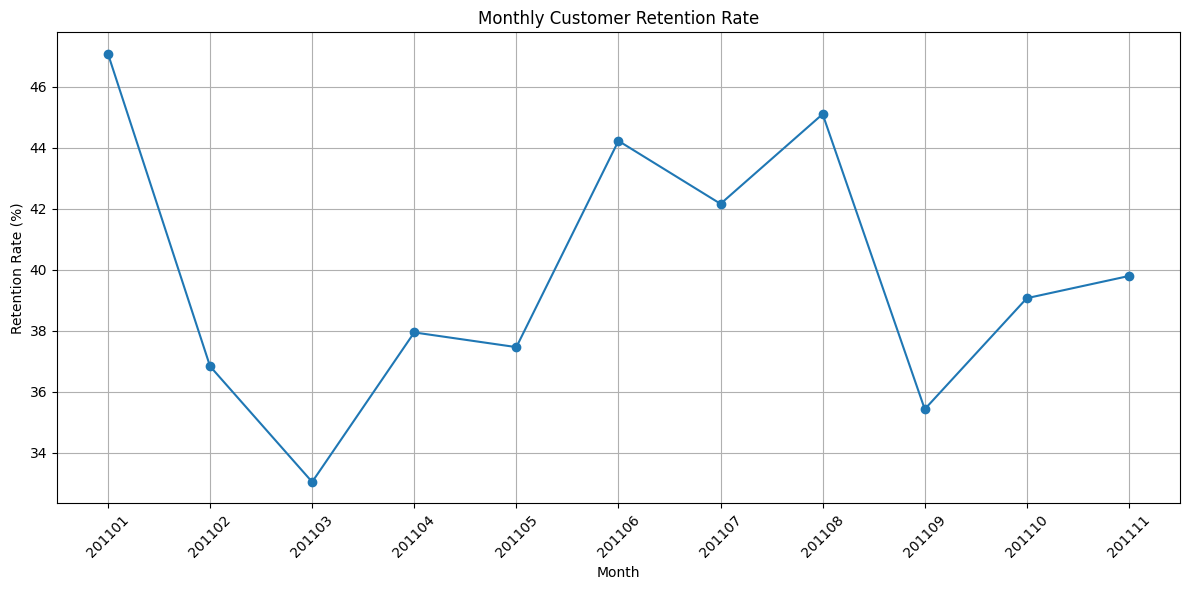

In [26]:
plot_data = retention_data[
    (retention_data['Month'] != 201112) &
    (retention_data['Month'] != 201012)
]

plt.figure(figsize=(12, 6))

plt.plot(
    plot_data['Month'].astype(str),
    plot_data['RetentionRate'],
    marker='o'
)

plt.title('Monthly Customer Retention Rate')
plt.xlabel('Month')
plt.ylabel('Retention Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()


We created a line chart to visualize the monthly customer retention rate.

We excluded December 2010 because its retention rate is NaN, as there is no previous-month data available.

We also excluded December 2011 because its data is incomplete.

The chart shows how the percentage of returning customers changes over time.